# RIPE with a lightweight backbone: final phase on Kaggle (2x T4)

DLCV course project, IIIT Sri City. 
Vanya Awasthi (S20230010251), Sai Greeshma Venkatanagari (S20230010259).

Adapted to Kaggle: **VGG-19 (original RIPE) vs hybrid encoder ResNet-18 (ours)** trained with the
same data, budget, seed, precision and hyperparameters, then evaluated on HPatches and MegaDepth-1500, plus three ResNet-18 ablations.
two GPUs used in parallel (one training run per GPU).

### Before the first run (once)
1. **Settings (right sidebar):** Accelerator = **GPU T4 x2**, Internet = **On** (needs a phone-verified account), Persistence = *Files only* if offered.
2. **Add-ons -> Secrets:** add `GH_TOKEN` (your read-only GitHub token for `RIPE-dlcv`) and switch "attached" on for this notebook.
3. **Data cache (saves ~3 h of GPU quota):** Kaggle cannot mount Google Drive, so Section B downloads `disk-data-560.tar` from Drive with `gdown`:
   share the file in Drive ("Anyone with the link", Viewer) and paste its file ID into `DRIVE_FILE_ID` in Section B.
   (Alternative: upload the tar as a private Kaggle Dataset and Add Input.) If neither is set, Section B downloads the data again.

### What is compared (identical to the Colab notebook)
| ID | Model | Trained by us |
|---|---|---|
| `official_vgg19_80k` | VGG-19, official weights | no (upper reference only) |
| `vgg19` | VGG-19, budget B | yes (fair baseline) |
| `resnet18` | ResNet-18 + full-res stem, budget B | yes (**main proposal**) |
| `resnet18_layer4` | + layer4 | yes (ablation) |
| `resnet18_narrowstem` | stem 16/32 | yes (ablation) |
| `resnet18_scratch` | no ImageNet init | yes (ablation) |
| `*_s1` | second seed | yes |

### Saving progress between sessions
Kaggle keeps `/kaggle/working` only for the session. **At the end of every session click "Save Version" (Save & Run All is not needed; Quick Save keeps the output files).**
In the next session: Add Input -> *Notebook Output* -> this notebook (your own previous version). Section A copies `runs/` back and
training resumes from `checkpoints/last.pth` (written every 250 steps).

## A. Setup (run every session)

In [1]:
import os, sys, subprocess, shutil, glob
from pathlib import Path
import torch
print('GPUs:', torch.cuda.device_count(), [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
print('CPUs:', os.cpu_count(), '| python', sys.version.split()[0], '| torch', torch.__version__)
assert torch.cuda.device_count() >= 1, 'Turn on a GPU accelerator (T4 x2) in the notebook settings'

GPUs: 2 ['Tesla T4', 'Tesla T4']
CPUs: 4 | python 3.13.16 | torch 2.11.0+cu130


In [2]:
WORK = Path('/kaggle/working')
RUNS, EVAL, FIGS = WORK / 'runs', WORK / 'eval', WORK / 'figures'
for d in (RUNS, EVAL, FIGS):
    d.mkdir(parents=True, exist_ok=True)

# locate the attached ripe-results dataset (Kaggle mounts it at /kaggle/input/datasets/<user>/<name>/)
found = []
for pat in ('/kaggle/input/*/runs', '/kaggle/input/*/*/runs', '/kaggle/input/*/*/*/runs'):
    found += [p for p in glob.glob(pat) if Path(p).is_dir()]
assert found, 'ripe-results is NOT attached: use Add Input -> your ripe-results dataset, then restart this cell'
RESTORE_ROOT = Path(found[0]).parent
print('restoring from', RESTORE_ROOT)

subprocess.run(['cp', '-rn', str(RESTORE_ROOT / 'runs') + '/.', str(RUNS)], check=False)
if (RESTORE_ROOT / 'eval').is_dir():
    subprocess.run(['cp', '-rn', str(RESTORE_ROOT / 'eval') + '/.', str(EVAL)], check=False)
if (RESTORE_ROOT / 'cost.json').exists():
    shutil.copy(RESTORE_ROOT / 'cost.json', WORK / 'cost.json')

print('runs present:', sorted(p.name for p in RUNS.iterdir()))
print('final models:', [str(p.relative_to(WORK)) for p in RUNS.glob('*/model_*_final.pth')])
print('eval contents:'); subprocess.run(f'ls {EVAL}/*', shell=True)
assert len(list(RUNS.glob('*/model_*_final.pth'))) >= 2, 'models not restored'

if (RESTORE_ROOT / 'ripe_weights.pth').exists():
    shutil.copy(RESTORE_ROOT / 'ripe_weights.pth', '/tmp/ripe_weights.pth')
    print('restored official weights')

restoring from /kaggle/input/datasets/vanyaawasthi/wave3-pkg


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


runs present: ['resnet18_s1', 'resnet18_s32000', 'resnet18_scratch_s32000', 'vgg19_s32000']
final models: ['runs/resnet18_scratch_s32000/model_6000_final.pth', 'runs/resnet18_s32000/model_6000_final.pth', 'runs/resnet18_s1/model_6000_final.pth', 'runs/vgg19_s32000/model_6000_final.pth']
eval contents:
/kaggle/working/eval/hpatches:
official_vgg19_80k
resnet18_s1
resnet18_s32000
resnet18_scratch_s32000
vgg19_s32000

/kaggle/working/eval/megadepth1500:
official_vgg19_80k
resnet18_s1
resnet18_s32000
resnet18_scratch_s32000
vgg19_s32000


In [3]:
roots = []
for z in glob.glob('/kaggle/input/**/wave*_pkg.zip', recursive=True):
    d = f'/tmp/{Path(z).stem}'
    subprocess.run(f'rm -rf {d} && mkdir -p {d} && unzip -q -o {z} -d {d}', shell=True)
    roots.append(Path(d))
for p in glob.glob('/kaggle/input/*/runs') + glob.glob('/kaggle/input/*/*/runs') + glob.glob('/kaggle/input/*/*/*/runs'):
    roots.append(Path(p).parent)
GF = Path('/kaggle/working/glue-factory/outputs/results'); GF.mkdir(parents=True, exist_ok=True)
for r in roots:
    print('merging', r)
    subprocess.run(f'cp -rn {r}/runs/. /kaggle/working/runs/', shell=True)
    if (r/'eval').is_dir(): subprocess.run(f'cp -rn {r}/eval/. /kaggle/working/eval/', shell=True)
    for g in (r/'glue-factory/outputs/results', r/'gluefactory_outputs/results'):
        if g.is_dir(): subprocess.run(f'cp -rn {g}/. {GF}/', shell=True)
    if (r/'cost.json').exists(): subprocess.run(f'cp -n {r}/cost.json /kaggle/working/cost.json', shell=True)
    if (r/'ripe_weights.pth').exists(): subprocess.run(f'cp -n {r}/ripe_weights.pth /tmp/ripe_weights.pth', shell=True)
print(sorted(p.name for p in RUNS.iterdir()))
!ls /kaggle/working/eval/*

merging /kaggle/input/datasets/vanyaawasthi/wave3-pkg


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


merging /kaggle/input/datasets/vanyaawasthi/wave4-pkg


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


merging /kaggle/input/datasets/vanyaawasthi/wave2-pkg


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


merging /kaggle/input/datasets/vanyaawasthi/updated-ripe-results


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


['resnet18_layer4_s32000', 'resnet18_narrowstem_s32000', 'resnet18_s1', 'resnet18_s32000', 'resnet18_scratch_s32000', 'vgg19_s1', 'vgg19_s32000']
/kaggle/working/eval/hpatches:
official_vgg19_80k	    resnet18_s1		     vgg19_s1
resnet18_layer4_s32000	    resnet18_s32000	     vgg19_s32000
resnet18_narrowstem_s32000  resnet18_scratch_s32000

/kaggle/working/eval/megadepth1500:
official_vgg19_80k	    resnet18_s1		     vgg19_s1
resnet18_layer4_s32000	    resnet18_s32000	     vgg19_s32000
resnet18_narrowstem_s32000  resnet18_scratch_s32000


In [4]:
# our repository (private): token from Kaggle Secrets, or a zip of the repo attached as a dataset
REPO = 'github.com/sheisstarwithoutmoon/RIPE-dlcv'
os.chdir('/kaggle/working')
if not Path('/kaggle/working/RIPE').exists():
    token = None
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret('GH_TOKEN')
    except Exception as e:
        print('no GH_TOKEN secret:', e)
    zips = glob.glob('/kaggle/input/*/RIPE-dlcv*.zip')
    if token:
        subprocess.run(['git', 'clone', '-q', f'https://x-access-token:{token}@{REPO}', 'RIPE'], check=True)
        subprocess.run(['git', '-C', 'RIPE', 'remote', 'set-url', 'origin', f'https://{REPO}'], check=True)   # do not keep the token in .git/config
    elif zips:
        subprocess.run(f'mkdir -p /tmp/rz && unzip -q -o {zips[0]} -d /tmp/rz', shell=True, check=True)
        src = next(p.parent for p in Path('/tmp/rz').rglob('ripe/train.py')).parent
        shutil.copytree(src, '/kaggle/working/RIPE')
        if not Path('/kaggle/working/RIPE/.git').exists():
            Path('/kaggle/working/RIPE/pyproject.toml').touch()      # ripe/train.py finds the project root via .git or pyproject.toml
    else:
        raise RuntimeError('Add the GH_TOKEN secret (Add-ons -> Secrets) or attach a dataset containing RIPE-dlcv.zip')
os.chdir('/kaggle/working/RIPE')
print(subprocess.run('git log --oneline | head -3; ls ripe/models/backbones/resnet.py scripts/prepare_disk_data.py', shell=True, capture_output=True, text=True).stdout)

4f032bb added changing from trapz to trapezoid
7e2a5dc implemented resnet-18 and other param diffs
52dd3a3 initial commit
ripe/models/backbones/resnet.py
scripts/prepare_disk_data.py



In [5]:
# NumPy 2 removed np.trapz (used by RIPE's validation). Idempotent patch that works on NumPy 1 and 2.
p = Path('/kaggle/working/RIPE/ripe/utils/pose_error.py')
t = p.read_text()
if 'np.trapz(r, x=e)' in t:
    p.write_text(t.replace('np.trapz(r, x=e)', "(np.trapezoid if hasattr(np, 'trapezoid') else np.trapz)(r, x=e)"))
    print('patched np.trapz')
else:
    print('np.trapz already handled')

np.trapz already handled


In [6]:
!pip install -q lightning hydra-core pyrootutils kornia wandb poselib h5py rich torchmetrics pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [7]:
os.environ['DATA_DIR'] = '/kaggle/working/data'                 # conf/data/*.yaml read ${DATA_DIR}/disk-data
os.environ['OUTPUT_DIR'] = str(RUNS)
os.environ['SLURM_JOB_ID'] = 'kaggle'                           # referenced by the default hydra run dir
os.environ['WANDB_MODE'] = 'disabled'                           # we log to CSV instead (train_metrics.csv)
os.environ['TORCH_HOME'] = '/kaggle/working/torch_cache'        # ImageNet weights are downloaded once per session
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

## B. Training data (DISK MegaDepth subset + IMW2020-val)
Unpacks the cached tar from the attached Kaggle Dataset (a minute or two). Without the dataset the subset is downloaded and resized again
(about 3 h on Colab; resumable).

In [8]:
BUDGET_GB = 40
# Option 1: the cache tar from Google Drive. In Drive: right-click disk-data-560.tar -> Share -> "Anyone with the link" (Viewer),
# copy the link  https://drive.google.com/file/d/<FILE_ID>/view  and paste only the FILE_ID below.
DRIVE_FILE_ID = ''
# Option 2: the tar attached as a Kaggle Dataset (found automatically under /kaggle/input).
cache = glob.glob('/kaggle/input/**/disk-data-560.tar', recursive=True)
# Kaggle sometimes unpacks uploaded archives: then the folder disk-data/ is already there
extracted = [Path(p).parent.parent for p in glob.glob('/kaggle/input/**/disk-data/megadepth/dataset.json', recursive=True)]
print('tar found:', cache, '| extracted folder found:', extracted)
if extracted and not cache and not Path('/kaggle/working/data/disk-data/megadepth/dataset.json').exists():
    !mkdir -p /kaggle/working/data && cp -r {extracted[0]} /kaggle/working/data/     # -> /kaggle/working/data/disk-data
ALLOW_FULL_DOWNLOAD = False   # True = download from EPFL (about 3 h and it burns GPU quota): only if you have no cache at all
if not Path('/kaggle/working/data/disk-data/megadepth/dataset.json').exists():
    if not (DRIVE_FILE_ID or cache or ALLOW_FULL_DOWNLOAD):
        raise RuntimeError('Cache not found. Attach your dataset (Add Input -> Datasets) or set DRIVE_FILE_ID. See: !ls -R /kaggle/input | head')
    if DRIVE_FILE_ID and not cache:
        !pip install -q gdown
        !gdown --id {DRIVE_FILE_ID} -O /kaggle/working/disk-data-560.tar
        cache = ['/kaggle/working/disk-data-560.tar']
    if cache:
        print('using cache', cache[0])
        !mkdir -p /kaggle/working/data && tar -xf {cache[0]} -C /kaggle/working/data
        if cache[0].startswith('/kaggle/working'):
            os.remove(cache[0])             # do not store the 2.3 GB tar in the saved output
    else:
        !python scripts/prepare_disk_data.py --root /kaggle/working/data/disk-data --budget-gb {BUDGET_GB} --workers {os.cpu_count()}
!du -sh /kaggle/working/data/disk-data/megadepth /kaggle/working/data/disk-data/imw2020-val
!python -c "import json; d=json.load(open('/kaggle/working/data/disk-data/megadepth/dataset.json')); print(len(d),'scenes,',sum(len(v['tuples']) for v in d.values()),'tuples')"

tar found: [] | extracted folder found: [PosixPath('/kaggle/input/datasets/vanyaawasthi/ripe-dlcv/disk-data')]
1.4G	/kaggle/working/data/disk-data/megadepth
886M	/kaggle/working/data/disk-data/imw2020-val
37 scenes, 362942 tuples


## C. Computational cost of all variants (no training)
Run this on the **same GPU type** you train on (T4). The numbers go into the cost figures.

In [18]:
!python compare_backbones.py --all --json {WORK}/cost.json

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
2026-11-18 20:22:24,039 - ripe.models.ripe - INFO - Training with window size 8.
2026-11-18 20:22:24,039 - ripe.models.ripe - INFO - Use None as final non-linearity before the detection heatmap.
2026-11-18 20:22:24,040 - ripe.models.ripe - INFO - Training dim reduction descriptor with 960 -> 256 1x1 conv
2026-11-18 20:22:34,271 - ripe.models.ripe - INFO - Training with window size 8.
2026-11-18 20:22:34,271 - ripe.models.ripe - INFO - Use None as final non-linearity before the detection

## D. Training budget

The budget is defined as a number of **training pairs**. The authors used 80,000 steps x 6 pairs = 480k pairs. On a T4 (15 GB) VGG-19 needs
batch 2 (x 12 accumulation = 24 pairs per optimizer update, same as the authors' 6 x 4), so **steps = pairs / 2**.

Measured on a Colab T4 at batch 2: VGG-19 about 4.9 s/step. `BUDGET_PAIRS = 12_000` -> 6000 steps -> about 8 h for VGG-19, ResNet-18 clearly less.
Both models of a wave run at the same time, one per GPU, with identical settings.

In [10]:
BATCH, ACCUM = 2, 12                     # 24 pairs per optimizer update (authors: 6 x 4)
PRECISION = '16-mixed'                   # T4 has no bf16; the same precision is used for every run
WORKERS = max(1, min(4, (os.cpu_count() or 4) // 2))   # two jobs share the CPUs

# ---- fix the budget here (identical for every run) ----
BUDGET_PAIRS = 12_000                    # 2.5% of the authors' 480k pairs
NUM_STEPS = BUDGET_PAIRS // BATCH
VAL_INTERVAL = NUM_STEPS // 10           # 11 points on the learning curve (+ final)
print(f'{PRECISION} batch {BATCH} x {ACCUM}, workers {WORKERS}: num_steps={NUM_STEPS}, validation every {VAL_INTERVAL} steps')

def train_cmd(run, backbone, num_steps=None, val_interval=None, seed=32000, out=RUNS):
    num_steps = NUM_STEPS if num_steps is None else num_steps
    val_interval = VAL_INTERVAL if val_interval is None else val_interval
    return (f'RIPE_SEED={seed} python ripe/train.py --config-name train '
            f'project_name=ripe_dlcv name={run} backbones={backbone} '
            f'num_steps={num_steps} val_interval={val_interval} batch_size={BATCH} num_grad_accs={ACCUM} '
            f'precision={PRECISION} num_workers={WORKERS} wandb_mode=disabled '
            f'hydra.run.dir={out}/{run}')

import time, re
def run_wave(jobs, poll=300):
    '''jobs: list of (run_name, backbone, seed), at most one per GPU. Runs them in parallel, one GPU each, and resumes finished/partial runs.'''
    procs = []
    n_gpu = torch.cuda.device_count()
    for i, (run, bb, seed) in enumerate(jobs):
        if list((RUNS / run).glob('model_*_final.pth')):
            print(run, 'already finished'); continue
        gpu = i % n_gpu
        log = open(WORK / f'{run}.log', 'a')
        cmd = train_cmd(run, bb, seed=seed)
        procs.append((run, gpu, subprocess.Popen(cmd, shell=True, stdout=log, stderr=subprocess.STDOUT,
                                                 env={**os.environ, 'CUDA_VISIBLE_DEVICES': str(gpu)}), log))
        print(f'started {run} on GPU {gpu}')
    while procs:
        time.sleep(poll)
        for run, gpu, pr, log in list(procs):
            tail = open(WORK / f'{run}.log', 'rb').read()[-400:].decode(errors='ignore').split('\r')[-1].strip()
            print(f'[{time.strftime("%H:%M")}] {run} (GPU {gpu}):', tail[-140:])
            if pr.poll() is not None:
                print(f'*** {run} exited with code {pr.returncode}', '(done)' if pr.returncode == 0 else '(see log)')
                procs.remove((run, gpu, pr, log))

16-mixed batch 2 x 12, workers 2: num_steps=6000, validation every 600 steps


### Optional: timing probe (5 min)
Check that both backbones fit in memory and see s/step before committing to a budget. Runs on GPU 0 only.

In [20]:
import pandas as pd
for bb in ['vgg', 'resnet']:
    shutil.rmtree(f'/kaggle/working/probe/probe_{bb}', ignore_errors=True)
    cmd = train_cmd(f'probe_{bb}', bb, num_steps=60, val_interval=0, out='/kaggle/working/probe')
    !CUDA_VISIBLE_DEVICES=0 {cmd} log_interval=10 ckpt_interval=0 2>&1 | tail -n 2
for bb in ['vgg', 'resnet']:
    f = f'/kaggle/working/probe/probe_{bb}/train_metrics.csv'
    if not os.path.exists(f):
        print(f'{bb:7s} FAILED (out of memory?)'); continue
    df = pd.read_csv(f)
    print(f'{bb:7s} sec/step (median) = {df.sec_per_step.iloc[2:].median():.2f}   peak GPU mem = {df.gpu_mem_gb.max():.1f} GB')
shutil.rmtree('/kaggle/working/probe', ignore_errors=True)

  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
LP: -0.0000 - Det: (2931.5000, 3143.0000), #mRwd: -26.8: 100%|██████████| 60/60 [02:30<00:00,  2.51s/it]
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
LP: 0.8718 - Det: (2917.5000, 2936.5000), #mRwd: 53.3: 100%|██████████| 60/60 [01:47<00:00,  1.79s/it]  
vgg     sec/step (median) = 2.43   peak GPU mem = 11.6 GB
resnet  sec/step (median) = 1.76   peak GPU mem = 6.8 GB


## E. Training runs (two per wave, one per GPU)

Waves are ordered by importance, stop after any wave if quota runs out. If the session ends, **Save Version**, attach it as input in the next
session, re-run A, B, D and re-run the same wave: unfinished runs resume from `checkpoints/last.pth`.
A run is complete when `model_<steps>_final.pth` exists. Logs: `<run>.log` (console), `runs/<run>/train_metrics.csv`, `val_metrics.csv`.

### Wave 1 (core): VGG-19 baseline || ResNet-18 (ours)

In [21]:
run_wave([('vgg19_s32000', 'vgg', 32000), ('resnet18_s32000', 'resnet', 32000)])

started vgg19_s32000 on GPU 0
started resnet18_s32000 on GPU 1
[20:33] vgg19_s32000 (GPU 0): LP: -0.0000 - Det: (2890.0000, 2878.0000), #mRwd: -23.0:   1%|          | 48/6000 [04:43<5:35:01,  3.38s/it]
[20:33] resnet18_s32000 (GPU 1): LP: 0.4079 - Det: (2915.0000, 3009.0000), #mRwd: 49.5:   2%|▏         | 104/6000 [04:48<4:07:08,  2.51s/it]
[20:38] vgg19_s32000 (GPU 0): LP: 0.3726 - Det: (2742.5000, 2712.0000), #mRwd: 17.0:   2%|▏         | 131/6000 [09:46<6:12:23,  3.81s/it]
[20:38] resnet18_s32000 (GPU 1): LP: 0.3002 - Det: (2832.5000, 3158.0000), #mRwd: 198.0:   4%|▎         | 213/6000 [09:47<4:09:41,  2.59s/it]
[20:43] vgg19_s32000 (GPU 0): LP: 0.3848 - Det: (2937.5000, 2561.0000), #mRwd: 41.0:   4%|▎         | 212/6000 [14:47<5:55:09,  3.68s/it]
[20:43] resnet18_s32000 (GPU 1): LP: 0.3467 - Det: (3421.5000, 3032.5000), #mRwd: 77.0:   5%|▌         | 319/6000 [14:48<4:51:15,  3.08s/it]
[20:48] vgg19_s32000 (GPU 0): LP: -0.0000 - Det: (3145.5000, 3123.0000), #mRwd: -31.3:   5%|▍     

### Wave 2 (ablations): ResNet-18 + layer4 || narrow stem

In [ ]:
run_wave([('resnet18_layer4_s32000', 'resnet_layer4', 32000), ('resnet18_narrowstem_s32000', 'resnet_narrowstem', 32000)])

### Wave 3: no ImageNet init || ResNet-18 second seed

In [ ]:
run_wave([('resnet18_scratch_s32000', 'resnet_scratch', 32000), ('resnet18_s1', 'resnet', 1)])

### Wave 4: VGG-19 second seed (alone on one GPU)

In [ ]:
run_wave([('vgg19_s1', 'vgg', 1)])

## F. Evaluation on HPatches and MegaDepth-1500
Same Glue Factory fork and `ripe+NN` protocol as the reproduction. `setup_gluefactory_ckpt.py` adds a config `ripe_ckpt+NN` (a copy of `ripe+NN`
with only the model loader changed). Run after a wave finishes; finished evaluations are skipped.

In [12]:
os.chdir('/kaggle/working')
!pip install -q uv
!apt-get install -y -q libeigen3-dev > /dev/null
![ -d glue-factory ] || git clone https://github.com/JohannesK14/glue-factory
os.chdir('/kaggle/working/glue-factory')
!git submodule update --init --recursive
!uv sync
!uv pip install pyyaml
!python /kaggle/working/RIPE/scripts/setup_gluefactory_ckpt.py /kaggle/working/glue-factory /kaggle/working/RIPE
os.chdir('/kaggle/working/RIPE')

Cloning into 'glue-factory'...
remote: Enumerating objects: 696, done.
remote: Counting objects: 100% (393/393), done.
remote: Compressing objects: 100% (191/191), done.
remote: Total 696 (delta 264), reused 202 (delta 202), pack-reused 303 (from 2)
Receiving objects: 100% (696/696), 3.26 MiB | 34.82 MiB/s, done.
Resolving deltas: 100% (387/387), done.
Submodule 'thirdparty/ripe' (https://github.com/fraunhoferhhi/RIPE.git) registered for path 'thirdparty/ripe'
Cloning into '/kaggle/working/glue-factory/thirdparty/ripe'...
Submodule path 'thirdparty/ripe': checked out 'e90c844f68b74c784099b39d625b1fbf8cdb0fd7'
Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: .venv
Resolved 180 packages in 1ms
Prepared 144 packages in 11m 23s                                         
░░░░░░░░░░░░░░░░░░░░ [0/144] Installing wheels...                               warning: Failed to hardlink files; falling back to full copy. This may lead to degraded performance.
   

In [13]:
gfo = RESTORE_ROOT / 'gluefactory_outputs'
dest = Path('/kaggle/working/glue-factory/outputs')
if gfo.is_dir():
    # results normally live in outputs/results/<benchmark>/<tag>
    target = dest if (gfo / 'results').is_dir() else dest / 'results'
    target.mkdir(parents=True, exist_ok=True)
    subprocess.run(['cp', '-rn', str(gfo) + '/.', str(target)], check=False)
    print('restored glue-factory outputs ->', target)
    subprocess.run(f'ls {target}/*', shell=True)

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


restored glue-factory outputs -> /kaggle/working/glue-factory/outputs/results
/kaggle/working/glue-factory/outputs/results/hpatches:
official_vgg19_80k

/kaggle/working/glue-factory/outputs/results/megadepth1500:
official_vgg19_80k


In [24]:
!wget -q --no-check-certificate https://cvg.hhi.fraunhofer.de/RIPE/ripe_weights.pth -O /tmp/ripe_weights.pth
!python scripts/eval_gluefactory.py --tag official_vgg19_80k --official --gf /kaggle/working/glue-factory --out {EVAL}

uv run python -m gluefactory.eval.hpatches --tag official_vgg19_80k --conf ripe+NN
Running benchmark: hpatches
Experiment tag: official_vgg19_80k
Config:
{'checkpoint': None,
 'data': {'batch_size': 1,
          'name': 'hpatches',
          'num_workers': 16,
          'preprocessing': {'resize': 480, 'side': 'short'}},
 'eval': {'estimator': 'poselib', 'ransac_th': 0.5},
 'model': {'extractor': {'name': 'extractors.ripe',
                         'threshold': 1.0,
                         'top_k': 1024},
           'ground_truth': {'name': None},
           'matcher': {'name': 'matchers.nearest_neighbor_matcher'},
           'name': 'two_view_pipeline'}}
[11/19/2026 05:17:03 gluefactory.eval.eval_pipeline INFO] Running eval pipeline HPatchesPipeline.
[11/19/2026 05:17:03 gluefactory.eval.eval_pipeline INFO] Loop 1: Exporting predictions to "/kaggle/working/glue-factory/outputs/results/hpatches/official_vgg19_80k".
RIPE Path: /kaggle/working/RIPE
Using existing weights from /tmp/ripe_

In [14]:
for run_dir in sorted(RUNS.iterdir()):
    ckpts = sorted(run_dir.glob('model_*_final.pth'))
    if ckpts:
        !python scripts/eval_gluefactory.py --tag {run_dir.name} --ckpt {ckpts[-1]} --gf /kaggle/working/glue-factory --out {EVAL}

uv run python -m gluefactory.eval.hpatches --tag resnet18_s32000 --conf ripe_ckpt+NN model.extractor.model_path=/kaggle/working/runs/resnet18_s32000/model_6000_final.pth
Running benchmark: hpatches
Experiment tag: resnet18_s32000
Config:
{'checkpoint': None,
 'data': {'batch_size': 1,
          'name': 'hpatches',
          'num_workers': 16,
          'preprocessing': {'resize': 480, 'side': 'short'}},
 'eval': {'estimator': 'poselib', 'ransac_th': 0.5},
 'model': {'extractor': {'model_path': '/kaggle/working/runs/resnet18_s32000/model_6000_final.pth',
                         'name': 'extractors.ripe_ckpt',
                         'threshold': 1.0,
                         'top_k': 1024},
           'ground_truth': {'name': None},
           'matcher': {'name': 'matchers.nearest_neighbor_matcher'},
           'name': 'two_view_pipeline'}}
[11/19/2026 11:32:27 gluefactory.eval.eval_pipeline INFO] Running eval pipeline HPatchesPipeline.
[11/19/2026 11:32:27 gluefactory.eval.eval_pipel

## G. Qualitative comparison

In [11]:
!wget -q --no-check-certificate https://cvg.hhi.fraunhofer.de/RIPE/ripe_weights.pth -O /tmp/ripe_weights.pth
!ls -lh /tmp/ripe_weights.pth

-rw-r--r-- 1 root root 57M Jun 26  2025 /tmp/ripe_weights.pth


Using existing weights from /tmp/ripe_weights.pth
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
2026-11-23 01:28:38,037 - ripe.models.ripe - INFO - Training with window size 8.
2026-11-23 01:28:38,038 - ripe.models.ripe - INFO - Use None as final non-linearity before the detection heatmap.
2026-11-23 01:28:38,038 - ripe.models.ripe - INFO - Training dim reduction descriptor with 960 -> 256 1x1 conv
VGG-19 official (80k steps): 2048/2048 kpts, 966 matches, 480 inliers (49.7%)
2026-11-23 01:28:45,726 - ripe.models.ripe - INFO - Train

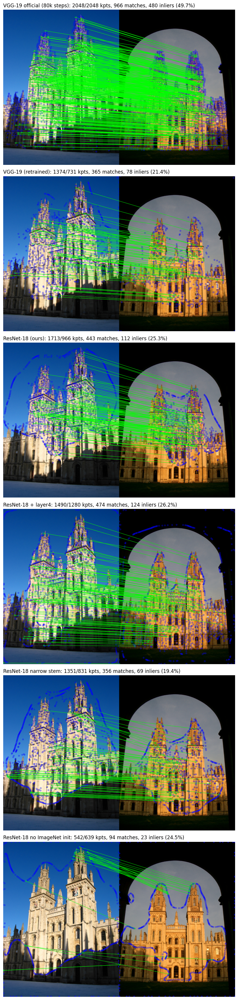

In [12]:
models = ['--model "VGG-19 official (80k steps)=official"']
for variant, label in [('vgg19', 'VGG-19 (retrained)'),
                       ('resnet18', 'ResNet-18 (ours)'),
                       ('resnet18_layer4', 'ResNet-18 + layer4'),
                       ('resnet18_narrowstem', 'ResNet-18 narrow stem'),
                       ('resnet18_scratch', 'ResNet-18 no ImageNet init')]:
    ck = sorted((RUNS / f'{variant}_s32000').glob('model_*_final.pth'))
    if ck:
        models.append(f'--model "{label}={ck[-1]}"')
!python scripts/qualitative.py {' '.join(models)} --out {FIGS}/fig_qualitative.png
from IPython.display import Image, display
display(Image(f'{FIGS}/fig_qualitative.png', width=900))

In [15]:
import glob
from IPython.display import Image, display

files = sorted(glob.glob('/kaggle/input/**/imw2020-val/scenes/st_peters_square/**/*.jpg', recursive=True))
print(len(files), 'images found')
IMG1, IMG2 = files[6], files[12]
print(IMG1, IMG2)

100 images found
/kaggle/input/datasets/vanyaawasthi/ripe-dlcv/disk-data/imw2020-val/scenes/st_peters_square/images/06795103_258881711.jpg /kaggle/input/datasets/vanyaawasthi/ripe-dlcv/disk-data/imw2020-val/scenes/st_peters_square/images/17068046_6824644790.jpg


Using existing weights from /tmp/ripe_weights.pth
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
2026-11-23 01:30:51,303 - ripe.models.ripe - INFO - Training with window size 8.
2026-11-23 01:30:51,303 - ripe.models.ripe - INFO - Use None as final non-linearity before the detection heatmap.
2026-11-23 01:30:51,303 - ripe.models.ripe - INFO - Training dim reduction descriptor with 960 -> 256 1x1 conv
VGG-19 official (80k steps): 2048/2048 kpts, 923 matches, 411 inliers (44.5%)
2026-11-23 01:30:54,638 - ripe.models.ripe - INFO - Train

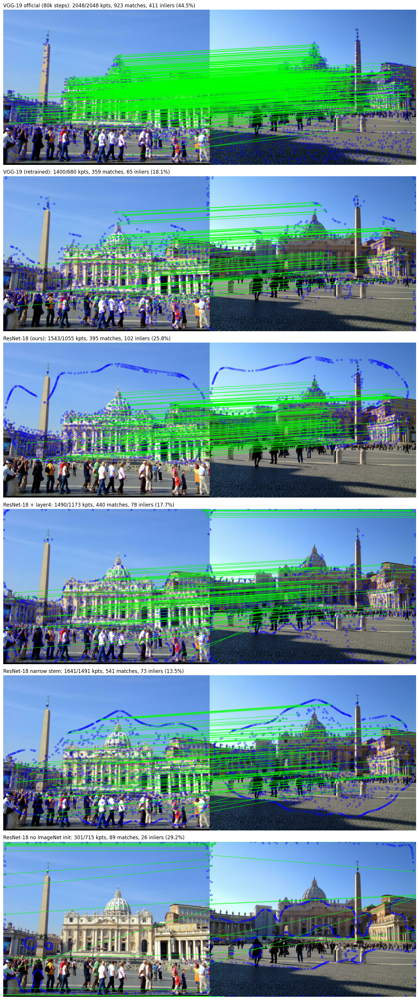

In [16]:
IMG1, IMG2 = files[6], files[12]
!python scripts/qualitative.py {' '.join(models)} --img1 {IMG1} --img2 {IMG2} --out {FIGS}/fig_qualitative_6_12.png
display(Image(f'{FIGS}/fig_qualitative_6_12.png', width=900))

## H. Figures and result table

Equal training budget: 6000 steps x 2 pairs. HP = HPatches homography AUC (px), MD = MegaDepth-1500 pose AUC (°).

| Model | #runs | HP@1 | HP@3 | HP@5 | MD@5 | MD@10 | MD@20 | Params (M) | ms/img | s/train step |
|---|---|---|---|---|---|---|---|---|---|---|
| VGG-19 official (80k steps) | 1 | 0.3803 | 0.5868 | 0.6924 | 0.5479 | 0.6771 | 0.7751 | 14.81 | 191.1 | - |
| VGG-19 (retrained) | 2 | 0.3220 ±0.0062 | 0.4837 ±0.0237 | 0.5859 ±0.0225 | 0.2876 ±0.0083 | 0.4125 ±0.0081 | 0.5344 ±0.0071 | 14.81 | 191.1 | 3.47 |
| ResNet-18 (ours) | 2 | 0.3148 ±0.0157 | 0.4422 ±0.0034 | 0.5403 ±0.0050 | 0.2901 ±0.0415 | 0.4199 ±0.0413 | 0.5432 ±0.0352 | 4.03 | 72.1 | 3.12 |
| ResNet-18 + layer4 | 1 | 0.3340 | 0.4904 | 0.5904 | 0.2629 | 0.3771 | 0.4899 | 15.49 | 76.1 | 3.45 |
| ResNet-18 narrow stem | 1 | 0.3248 | 0.4590 | 0.5604 | 0.2078 | 0.3148 | 0.4294 | 3.96 | 42.7 | 3.50 |
| ResNet-18 no ImageNet init | 1 | 0.3553 | 0.3860 | 0.4017 | 0.0009 | 0.0033 | 0.0175 | 4.03 | 72.1 | 2.99 |
figures writ

**fig_training_curves**

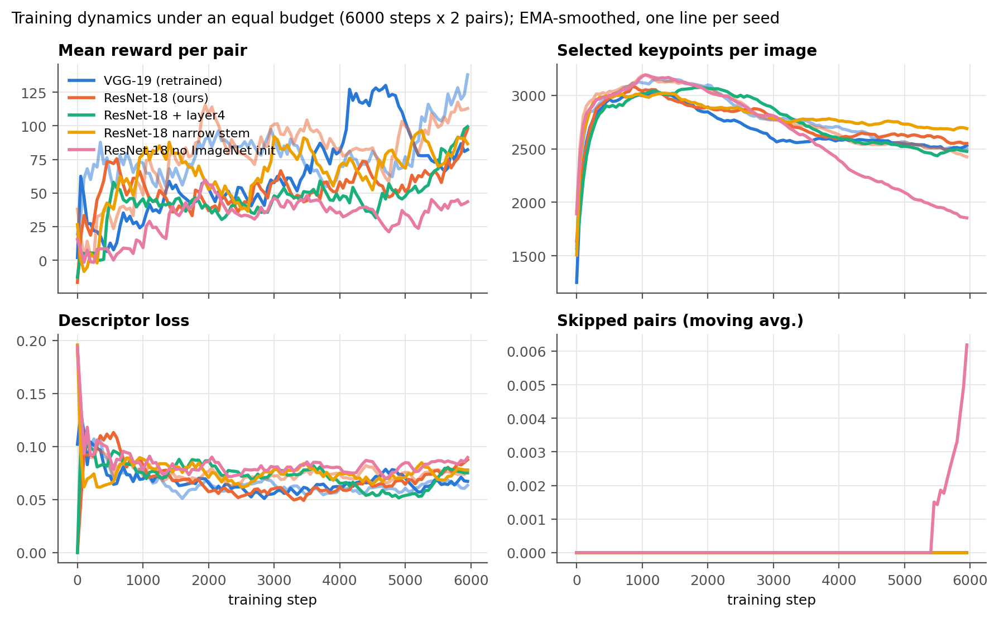

**fig_val_auc**

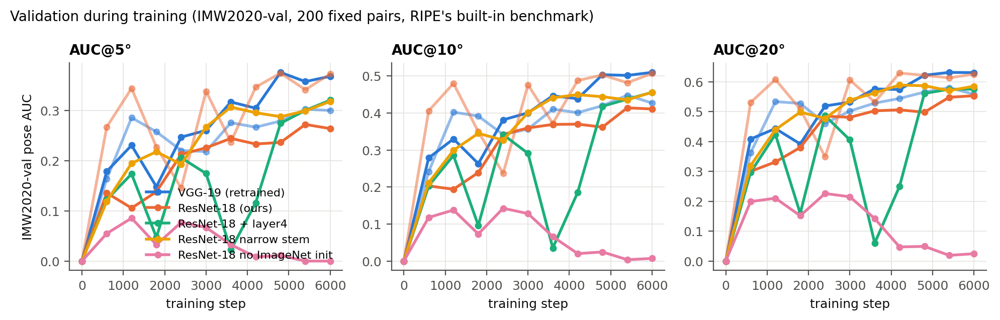

**fig_hpatches_auc**

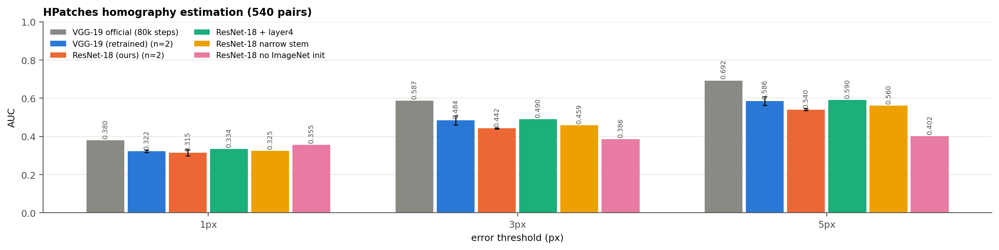

**fig_megadepth1500_auc**

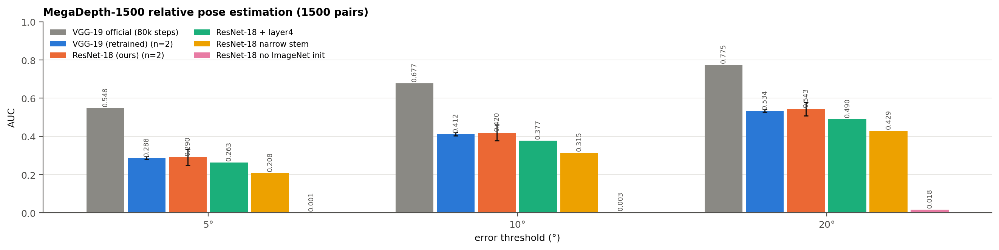

**fig_cumulative_errors**

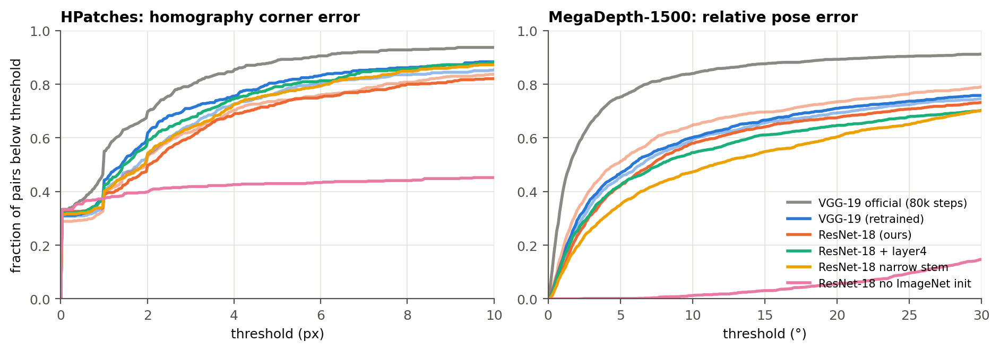

**fig_cost_relative**

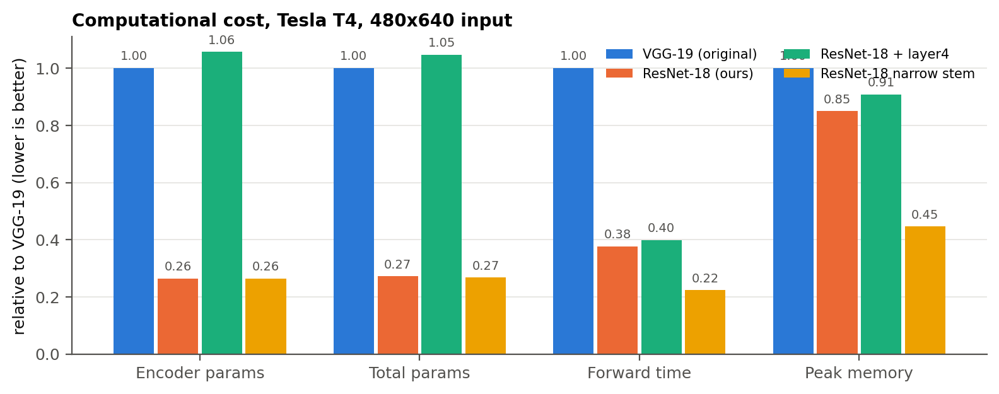

**fig_accuracy_vs_cost**

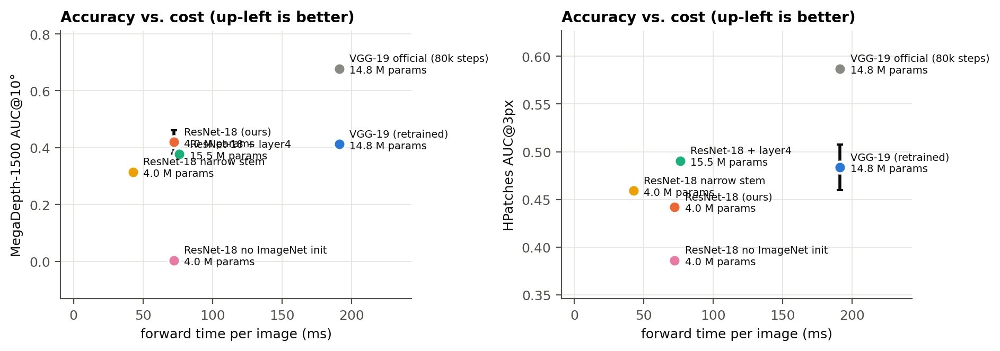

Equal training budget: 6000 steps x 2 pairs. HP = HPatches homography AUC (px), MD = MegaDepth-1500 pose AUC (°).

| Model | #runs | HP@1 | HP@3 | HP@5 | MD@5 | MD@10 | MD@20 | Params (M) | ms/img | s/train step |
|---|---|---|---|---|---|---|---|---|---|---|
| VGG-19 official (80k steps) | 1 | 0.3803 | 0.5868 | 0.6924 | 0.5479 | 0.6771 | 0.7751 | 14.81 | 191.1 | - |
| VGG-19 (retrained) | 2 | 0.3220 ±0.0062 | 0.4837 ±0.0237 | 0.5859 ±0.0225 | 0.2876 ±0.0083 | 0.4125 ±0.0081 | 0.5344 ±0.0071 | 14.81 | 191.1 | 3.47 |
| ResNet-18 (ours) | 2 | 0.3148 ±0.0157 | 0.4422 ±0.0034 | 0.5403 ±0.0050 | 0.2901 ±0.0415 | 0.4199 ±0.0413 | 0.5432 ±0.0352 | 4.03 | 72.1 | 3.12 |
| ResNet-18 + layer4 | 1 | 0.3340 | 0.4904 | 0.5904 | 0.2629 | 0.3771 | 0.4899 | 15.49 | 76.1 | 3.45 |
| ResNet-18 narrow stem | 1 | 0.3248 | 0.4590 | 0.5604 | 0.2078 | 0.3148 | 0.4294 | 3.96 | 42.7 | 3.50 |
| ResNet-18 no ImageNet init | 1 | 0.3553 | 0.3860 | 0.4017 | 0.0009 | 0.0033 | 0.0175 | 4.03 | 72.1 | 2.99 |


In [17]:
!python scripts/plot_results.py --runs-dir {RUNS} --eval-dir {EVAL} --cost-json {WORK}/cost.json --out {FIGS} --budget "{NUM_STEPS} steps x {BATCH} pairs"
from IPython.display import Image, display, Markdown
for f in ['fig_training_curves', 'fig_val_auc', 'fig_hpatches_auc', 'fig_megadepth1500_auc',
          'fig_cumulative_errors', 'fig_cost_relative', 'fig_accuracy_vs_cost']:
    p = FIGS / f'{f}.png'
    if p.exists():
        display(Markdown(f'**{f}**')); display(Image(str(p), width=850))
display(Markdown((FIGS / 'results_table.md').read_text()))

In [18]:
!rm -rf /kaggle/working/PKG && mkdir -p /kaggle/working/PKG/gluefactory_outputs
!cd /kaggle/working && cp -r runs eval figures cost.json PKG/
!cp /tmp/ripe_weights.pth /kaggle/working/PKG/ripe_weights.pth
!cp -r /kaggle/working/glue-factory/outputs/results /kaggle/working/PKG/gluefactory_outputs/
# drop only the heavy training checkpoints; keep model_*_final.pth and eval/*/results.h5
!find /kaggle/working/PKG/runs -name checkpoints -type d -exec rm -rf {} +
# drop only the big .h5 files inside the glue-factory outputs
!find /kaggle/working/PKG/gluefactory_outputs -name "*.h5" -delete
!cd /kaggle/working && zip -rq updated-ripe-results-v2.zip PKG && ls -lh updated-ripe-results-v2.zip
# sanity check: should list 7 per benchmark, and 6 final models
!find /kaggle/working/PKG/eval -name results.h5 | wc -l
!find /kaggle/working/PKG/runs -name "model_*_final.pth" | wc -l

-rw-r--r-- 1 root root 286M Nov 23 01:32 updated-ripe-results-v2.zip
16
7
